# 04 · Power simulation

**Phase:** pre-freeze (plan §7.2 item 6). **Looks at outcomes vs predictors?** No. The label column `y` is dropped on load. The only outcome information used is the event **rate** per period (development vs locked), which the audits already report. Every label in this notebook is synthetic.

**What it does.** It plants a known effect in synthetic events on the real panel structure: the real stage-1 risk set, real features, real observability and real country clustering. It then runs the confirmatory pipeline: annual refits over 2005–2024, intercept updating, persistence baseline and country-clustered bootstrap. For each hypothesis and horizon it records how often the decision rule passes. Full description: `src/flypredictor/eval/power.py`.

**Outputs** (`results/dev/power/`):

| File | Content |
|---|---|
| `power_table.csv` | power by hypothesis × horizon × scenario, with median estimates |
| `mde.csv` | minimum detectable effect per hypothesis × horizon (δ in the pre-registration is this MDE, not a pass threshold; D-20b) |
| `h1_confirmatory.csv` | power of the confirmatory H1 rule: *k* = 1 **and** *k* = 2 pass in the same dataset (D-20b) |
| `stand_in_check.csv` | ridge stand-in vs elastic net on the same simulated datasets (why ridge is primary; D-20b) |
| `sim_raw.parquet` | every simulated test (git-ignored) |

**Run time.** The run cell first times one simulated dataset and prints an estimate for the full run. It then prints a line after each of the 7 scenarios. Each finished scenario is saved in `results/dev/power/sim_parts/`, so if you interrupt the kernel, re-running the cell resumes where it stopped. Set `QUICK = True` for a smoke test. Once the run is complete, `sim_raw.parquet` is reused unless `RERUN = True` (delete `sim_parts/` too to recompute from scratch).

In [1]:
QUICK = False   # True: 3 reps per scenario, for a smoke test
RERUN = False   # True: ignore the cached simulation and run again

from flypredictor import load_config, Paths
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from flypredictor.data import episodes, states as S, ert_jobs, features
from flypredictor.eval import power
from flypredictor.models.baselines import tercile_cuts

cfg = load_config()
paths = Paths.from_root().ensure()
out = paths.results / "dev" / "power"
out.mkdir(parents=True, exist_ok=True)

panel = pd.read_parquet(paths.panel_parquet)
labels_no_y = pd.read_parquet(paths.labels_parquet).drop(columns="y")   # observability only
st = pd.read_parquet(paths.states_parquet)
feats = features.build_features(panel, cfg)
print(feats.shape, "| clean features:", len(features.feature_columns(cfg, "clean")), "| full:", len(features.feature_columns(cfg, "full")))

(19857, 118) | clean features: 59 | full: 115


## 1 · Calibration targets (event rates only) and the planted signal

In [2]:
ert = episodes.load_ert(paths)
eps = episodes.democratic_episodes(ert, cfg)
ev = episodes.split_declarations(episodes.country_events(eps, ert_jobs.load_realtime(paths), ert), st)

rates = {e: power.target_rates(ev, st, cfg, e) for e in ("declaration", "breakdown")}
g = power.target_rates(ev, st, cfg, "declaration_dem")
gradual_share = {p: g[p] / rates["declaration"][p] for p in g}
cuts = tercile_cuts(feats, cfg)
pdat = power.prepare(feats, labels_no_y, cfg)

display(pd.DataFrame(rates).T.rename_axis("event per stage-1 year"))
print("gradual share of declarations:", {k: round(v, 3) for k, v in gradual_share.items()})
print("persistence tercile cuts (3-year EDI change):", np.round(cuts, 4))
print("signal features:", power.SIGNAL_FEATURES)
print("corr(leading signal, mechanical signal) =", round(float(np.corrcoef(pdat.signal, pdat.mech)[0, 1]), 3))

,development,locked
event per stage-1 year,,
declaration,0.011057,0.029859
breakdown,0.010749,0.009014


gradual share of declarations: {'development': 0.194, 'locked': 0.755}
persistence tercile cuts (3-year EDI change): [0.    0.011]
signal features: ['v2cacamps', 'v2caviol__d3', 'v2x_jucon__d3', 'v2xlg_legcon__d3', 'v2exrescon__d3', 'v2regsupgroupssize__d3']
corr(leading signal, mechanical signal) = 0.717


## 2 · Run the simulation

Scenarios: a true null (no signal at all), then β ∈ `power.effect_sizes` with the mechanical effect fixed at `power.mechanical_beta`. β = 0 with the mechanical effect is the null for H2a: leading groups add nothing beyond the slide itself.

In [3]:
raw_file = out / "sim_raw.parquet"
if raw_file.is_file() and not RERUN and not QUICK:
    sim = pd.read_parquet(raw_file)
    print("loaded cached simulation:", sim.shape)
else:
    import time
    # Timing check: one simulated dataset on one core, so you know what to expect.
    t0 = time.time()
    power.one_rep(pdat, cfg, (1.0, float(cfg["power"]["mechanical_beta"])), 0, rates, gradual_share, cuts,
                  cfg["power"]["model"], {"C": float(cfg["power"]["ridge_C"])})
    one = time.time() - t0
    import os
    n_rep = 3 if QUICK else int(cfg["power"]["reps"])
    total = one * n_rep * len(power.scenarios(cfg)) / max(1, (os.cpu_count() or 2) // 2)
    print(f"one dataset: {one:.0f} s -> full run roughly {total / 60:.0f} min "
          f"({os.cpu_count()} logical cores; progress is printed after each scenario)")
    # Each finished scenario is saved in sim_parts/ and skipped if the cell is re-run (resume after an interruption).
    sim = power.run(pdat, cfg, rates, gradual_share, cuts, reps=n_rep,
                    checkpoint_dir=None if QUICK else out / "sim_parts")
    print("simulation finished:", sim.shape)
    if not QUICK:
        sim.to_parquet(raw_file, index=False)

loaded cached simulation: (19600, 14)


## 3 · Power and minimum detectable effects

* `false_positive_rate`: pass rate with no signal at all. It should be at or below about 2.5%, because the decision rules are one-sided at the 95% level.
* `leading_null_rate`: pass rate with only the mechanical slide signal. For H2a this is the type-I error.
* `mde_beta`: the smallest β with ≥ 80% power. `metric_at_mde` is the median estimate there (Brier skill, or Δ log loss for H2a); the pre-registration reports δ as the effect the design is powered for (D-20b, D-20c). It is not a pass threshold: tests pass when their intervals exclude the baseline (decision D-20b). `oracle_auc_at_mde` translates β into the AUC that the *true* probabilities would reach at *k* = 1.
* No `mde_beta` means the hypothesis is underpowered across the whole grid. The pre-registration then reports it as estimation only.

In [4]:
agg, mde = power.summarise(sim, float(cfg["power"]["target_power"]))
if not QUICK:
    agg.to_csv(out / "power_table.csv", index=False)
    mde.to_csv(out / "mde.csv", index=False)
mde.round(3)

,task,k,false_positive_rate,leading_null_rate,metric,mde_beta,power_at_mde,metric_at_mde,oracle_auc_at_mde
0,H1,1,0.000,0.005,brier_skill,2.0,0.850,0.069,0.822
1,H1,2,0.000,0.000,brier_skill,2.0,0.850,0.061,0.822
2,H1,3,0.010,0.005,brier_skill,3.0,0.975,0.102,0.912
3,H1,5,0.005,0.005,brier_skill,NaN,0.690,NaN,NaN
4,H1,all,0.000,0.000,brier_skill,NaN,0.690,NaN,NaN
5,H1b,1,0.000,0.000,brier_skill,3.0,0.950,0.145,0.912
6,H1b,2,0.000,0.000,brier_skill,3.0,0.945,0.125,0.912
7,H1b,3,0.000,0.005,brier_skill,3.0,0.915,0.100,0.912
8,H1b,5,0.005,0.000,brier_skill,NaN,0.565,NaN,NaN
9,H2a,3,0.000,0.000,delta_log_loss,3.0,0.980,0.025,0.912


In [5]:
# Confirmatory H1 rule (decision D-20b): k = 1 AND k = 2 must both pass in the same simulated dataset.
target = float(cfg["power"]["target_power"])
h1 = sim[(sim.task == "H1") & sim.k.astype(str).isin(["1", "2"])].assign(k=lambda d: d.k.astype(str))
joint = (h1.pivot_table(index=["scenario", "beta", "beta_mech", "rep"], columns="k", values="pass", aggfunc="first")
           .astype(bool).all(axis=1).rename("pass").reset_index())
h1_conf = (joint.groupby(["scenario", "beta", "beta_mech"], as_index=False)["pass"].mean()
                .rename(columns={"pass": "power"}).sort_values(["beta_mech", "beta"]))
signal = h1_conf[h1_conf.beta_mech > 0]
reach = signal[signal.power >= target]
mde_beta = float(reach.beta.min()) if len(reach) else None
if not QUICK:
    h1_conf.to_csv(out / "h1_confirmatory.csv", index=False)
print("Confirmatory H1 rule (k = 1 and 2): power by beta")
display(h1_conf.round(3))
print("MDE beta at", target, "power:", mde_beta if mde_beta is not None else "not reached on the grid",
      "| power at beta = 2:", round(float(signal.loc[signal.beta == 2.0, "power"].iloc[0]), 3))


Confirmatory H1 rule (k = 1 and 2): power by beta


,scenario,beta,beta_mech,power
0,"beta=0, mech=0",0.0,0.0,0.000
1,"beta=0, mech=0.5",0.0,0.5,0.000
2,"beta=0.5, mech=0.5",0.5,0.5,0.000
3,"beta=1, mech=0.5",1.0,0.5,0.045
4,"beta=1.5, mech=0.5",1.5,0.5,0.345
5,"beta=2, mech=0.5",2.0,0.5,0.765
6,"beta=3, mech=0.5",3.0,0.5,0.995


MDE beta at 0.8 power: 3.0 | power at beta = 2: 0.765


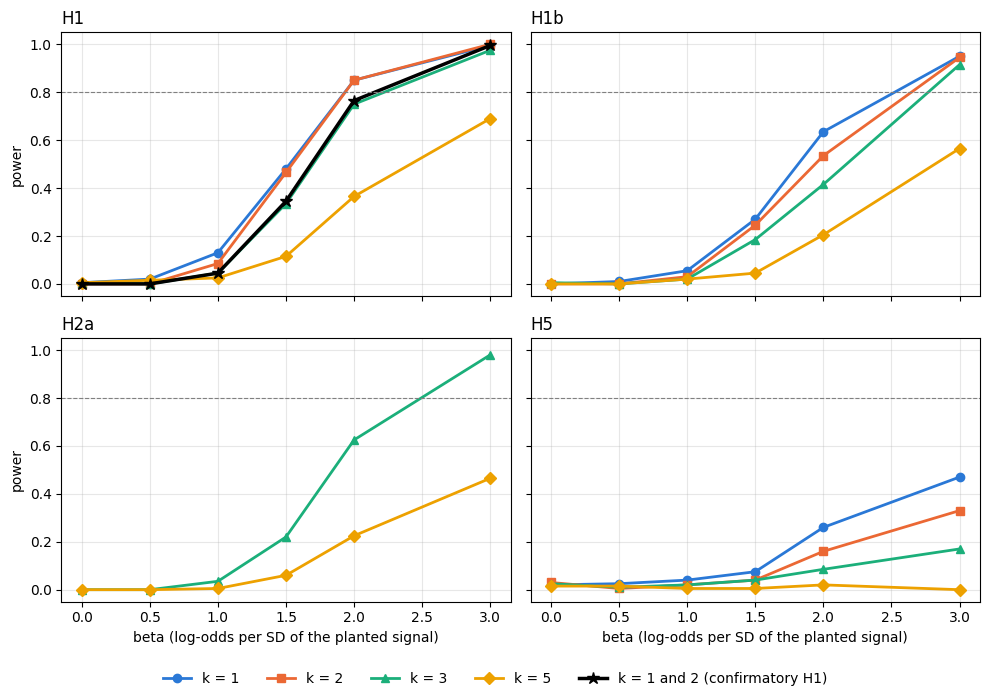

In [6]:
# One fixed colour and marker per horizon in every panel (colour follows k, never the plotting order).
# Palette checked for colour-blind separation; markers carry identity too.
COLORS = {"1": "#2a78d6", "2": "#eb6834", "3": "#1baf7a", "5": "#eda100"}
MARKERS = {"1": "o", "2": "s", "3": "^", "5": "D"}
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for ax, task in zip(axes.ravel(), ["H1", "H1b", "H2a", "H5"]):
    d = agg[(agg.task == task) & (agg.beta_mech > 0)]
    for k in ["1", "2", "3", "5"]:
        g = d[d.k.astype(str) == k].sort_values("beta")
        if len(g):
            ax.plot(g.beta, g.power, color=COLORS[k], marker=MARKERS[k], lw=2, label=f"k = {k}")
    if task == "H1":   # the confirmatory rule (D-20b)
        g = h1_conf[h1_conf.beta_mech > 0].sort_values("beta")
        ax.plot(g.beta, g.power, color="black", marker="*", ms=9, lw=2.5, label="k = 1 and 2 (confirmatory H1)")
    ax.axhline(cfg["power"]["target_power"], color="grey", lw=0.8, ls="--")
    ax.set_title(task, loc="left")
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("beta (log-odds per SD of the planted signal)")
for ax in axes[:, 0]:
    ax.set_ylabel("power")
handles, labs = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labs, loc="lower center", ncol=5, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
if not QUICK:
    fig.savefig(paths.figures / "power_curves.png", dpi=150)


In [7]:
# How strong is each scenario? Oracle AUC and the median number of locked-test positives.
cols = ["task", "k", "beta", "beta_mech", "power", "median_positives", "median_brier_skill", "median_ap_ratio", "median_oracle_auc"]
agg[(agg.k == "1") & agg.task.isin(["H1", "H5"])][[c for c in cols if c in agg]].round(3)

,task,k,beta,beta_mech,power,median_positives,median_brier_skill,median_ap_ratio,median_oracle_auc
0,H1,1,0.0,0.0,0.000,52.0,-0.001,1.059,0.500
1,H1,1,0.0,0.5,0.005,51.0,-0.002,1.072,0.545
2,H1,1,0.5,0.5,0.020,49.0,-0.001,1.316,0.609
3,H1,1,1.0,0.5,0.130,50.0,0.008,2.341,0.682
4,H1,1,1.5,0.5,0.480,50.0,0.032,4.062,0.758
5,H1,1,2.0,0.5,0.850,48.0,0.069,6.939,0.822
6,H1,1,3.0,0.5,0.995,48.0,0.151,12.306,0.912
84,H5,1,0.0,0.0,0.020,12.0,0.001,1.190,0.500
85,H5,1,0.0,0.5,0.020,12.0,0.001,1.132,0.546
86,H5,1,0.5,0.5,0.025,11.0,0.001,1.341,0.590


## 4 · Stand-in check: ridge vs elastic net

The simulation uses a ridge logit because the elastic net (saga) is about 300× slower, and annual refits need ~240 fits per dataset. Here both models score the **same** simulated datasets, with a frozen fit (the elastic net is too slow for annual refits here). If their Brier skill and pass rates agree, the power numbers carry over to the elastic net.

**Result (2026-10-10):** they do not. On 10 datasets at β = 2 the elastic net (C = 0.1, l1_ratio = 0.5) failed in 28 paired cases where ridge passed, and never the reverse. The simulated power therefore applies to ridge, which is why **ridge is the primary confirmatory model** (decision D-20b); the elastic net and lasso stay in the lineup.

In [8]:
chk_file = out / "stand_in_check.csv"
if chk_file.is_file() and not RERUN and not QUICK:
    chk = pd.read_csv(chk_file)
else:
    chk = power.stand_in_check(pdat, cfg, rates, gradual_share, cuts, reps=2 if QUICK else 10, beta=2.0)
    if not QUICK:
        chk.to_csv(chk_file, index=False)
chk.groupby(["model", "task", "k"])[["brier_skill", "ap_ratio", "pass"]].mean().unstack("model").round(3)

brier_skill        ap_ratio        pass      
model         enet  ridge     enet  ridge enet ridge
task k                                              
H1   1       0.060  0.031    7.407  6.592  0.7   0.8
     2       0.062  0.042    3.864  3.718  0.8   1.0
     3       0.049  0.042    2.690  2.689  0.6   1.0
     5       0.020  0.024    1.704  1.710  0.3   0.6
H1b  1       0.051  0.029    8.202  7.656  0.6   0.8
     2       0.048  0.040    3.970  3.980  0.4   0.9
     3       0.034  0.037    2.719  2.809  0.3   0.7
     5       0.011  0.020    1.726  1.735  0.3   0.4
H2a  3         NaN    NaN      NaN    NaN  0.3   0.7
     5         NaN    NaN      NaN    NaN  0.0   0.2

## Reading guide and decisions taken (D-20b, 2026-10-19)

1. **H1 / all** (every *k* must pass) has only about 32% power at β = 2. *k* = 5 is the bottleneck. The confirmatory rule is therefore **H1 at *k* = 1 and 2** (`h1_confirmatory.csv`: 76.5% at β = 2, 99.5% at β = 3). *k* = 3 and 5 are reported as the decay curve with intervals.
2. **δ₁** ≈ 0.06 Brier skill (oracle AUC ≈ 0.82) is the **design effect** at β = 2, where the confirmatory rule has 76.5% power. The strict 80% MDE lies between β = 2 and 3 on this grid (D-20c). δ is not a pass threshold.
3. **H1b** (64% at β = 2, *k* = 1), **H2a** (62% at *k* = 3; 22% at *k* = 5) and **H5** (≤ 47% even at β = 3) are **estimation only**: intervals, no verdict. H3 and H4 were not simulated and are estimation only.
4. With one confirmatory hypothesis, no Holm correction is needed.
5. **Type-I error:** pass rates at β = 0 are 0–3.5%, within Monte Carlo error of the nominal 2.5%.
6. The **primary model is ridge** (section 4). All of this is written into `prereg/preregistration.md` §2.
